In [1]:
modules = ["pandas", "numpy", "missingno", "seaborn", "matplotlib"]

import sys
import os.path
from subprocess import check_call
import importlib
import os

def instala(modules):
  print("Instalando módulos")
  for m in modules:
      # para el import quitamos [...] y ==...
      p = m.find("[")
      mi = m if p==-1 else m[:p]
      p = mi.find("==")
      mi = mi if p==-1 else mi[:p]

      torch_loader = importlib.util.find_spec(mi)
      if torch_loader is not None:
          print(m," encontrado")
      else:
          print(m," No encontrado, instalando...",end="")  
          try:        
            r = check_call([sys.executable, "-m", "pip", "install", "--user", m])
            print("¡hecho! (Reiniciar kernel)")
          except:
            print("¡Problema al instalar ",m,"! ¿seguro que el módulo existe?",sep="")
              
  print("¡Terminado!")

instala(modules)

Instalando módulos
pandas  encontrado
numpy  encontrado
missingno  encontrado
seaborn  encontrado
matplotlib  encontrado
¡Terminado!


In [2]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
path = r'../../data/limpieza/cleaned_data.csv'
df = pd.read_csv(path, header=0)
df

,timestamp,open_binance,high_binance,low_binance,close_binance,volume_binance,trades_binance,volumen_binance,SMA_50_binance,SMA_200_binance,...,SMA_200_dxy,EMA_50_dxy,EMA_200_dxy,volatilidad_50_dxy,volatilidad_200_dxy,momentum_50_dxy,momentum_200_dxy,var_diaria_dxy,rango_dia_dxy,RSI_dxy
0,2022-03-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,96.349363,96.226579,NaN,NaN,NaN,NaN,0.879436,1.080002,77.238708
1,2022-03-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-03-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-03-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,96.464682,96.257061,NaN,NaN,NaN,NaN,0.648758,0.849998,79.462488
4,2022-03-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,96.566459,96.284951,NaN,NaN,NaN,NaN,-0.231648,0.610001,68.885196
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1093,2025-03-01,84349.95,86558.00,83824.78,86064.53,25785.05464,3700728.0,2.219179e+09,97742.7420,82128.37695,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1094,2025-03-02,86064.54,95000.00,85050.60,94270.00,54889.09045,7403218.0,5.174395e+09,97736.1422,82306.31000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1095,2025-03-03,94269.99,94416.46,85117.11,86220.61,59171.10218,9797860.0,5.101769e+09,97569.6532,82449.70775,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1096,2025-03-04,86221.16,86807.98,81500.00,85509.59,41800.31065,8123921.0,3.574327e+09,97389.1230,82582.88270,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1098 entries, 0 to 1097
Data columns (total 90 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   timestamp                    1098 non-null   object 
 1   open_binance                 1001 non-null   float64
 2   high_binance                 1001 non-null   float64
 3   low_binance                  1001 non-null   float64
 4   close_binance                1001 non-null   float64
 5   volume_binance               1001 non-null   float64
 6   trades_binance               1001 non-null   float64
 7   volumen_binance              1001 non-null   float64
 8   SMA_50_binance               952 non-null    float64
 9   SMA_200_binance              802 non-null    float64
 10  EMA_50_binance               1001 non-null   float64
 11  EMA_200_binance              1001 non-null   float64
 12  var_diaria_binance           1000 non-null   float64
 13  volatilidad_50_bin

## 1. Conteo de nulos

<Axes: >

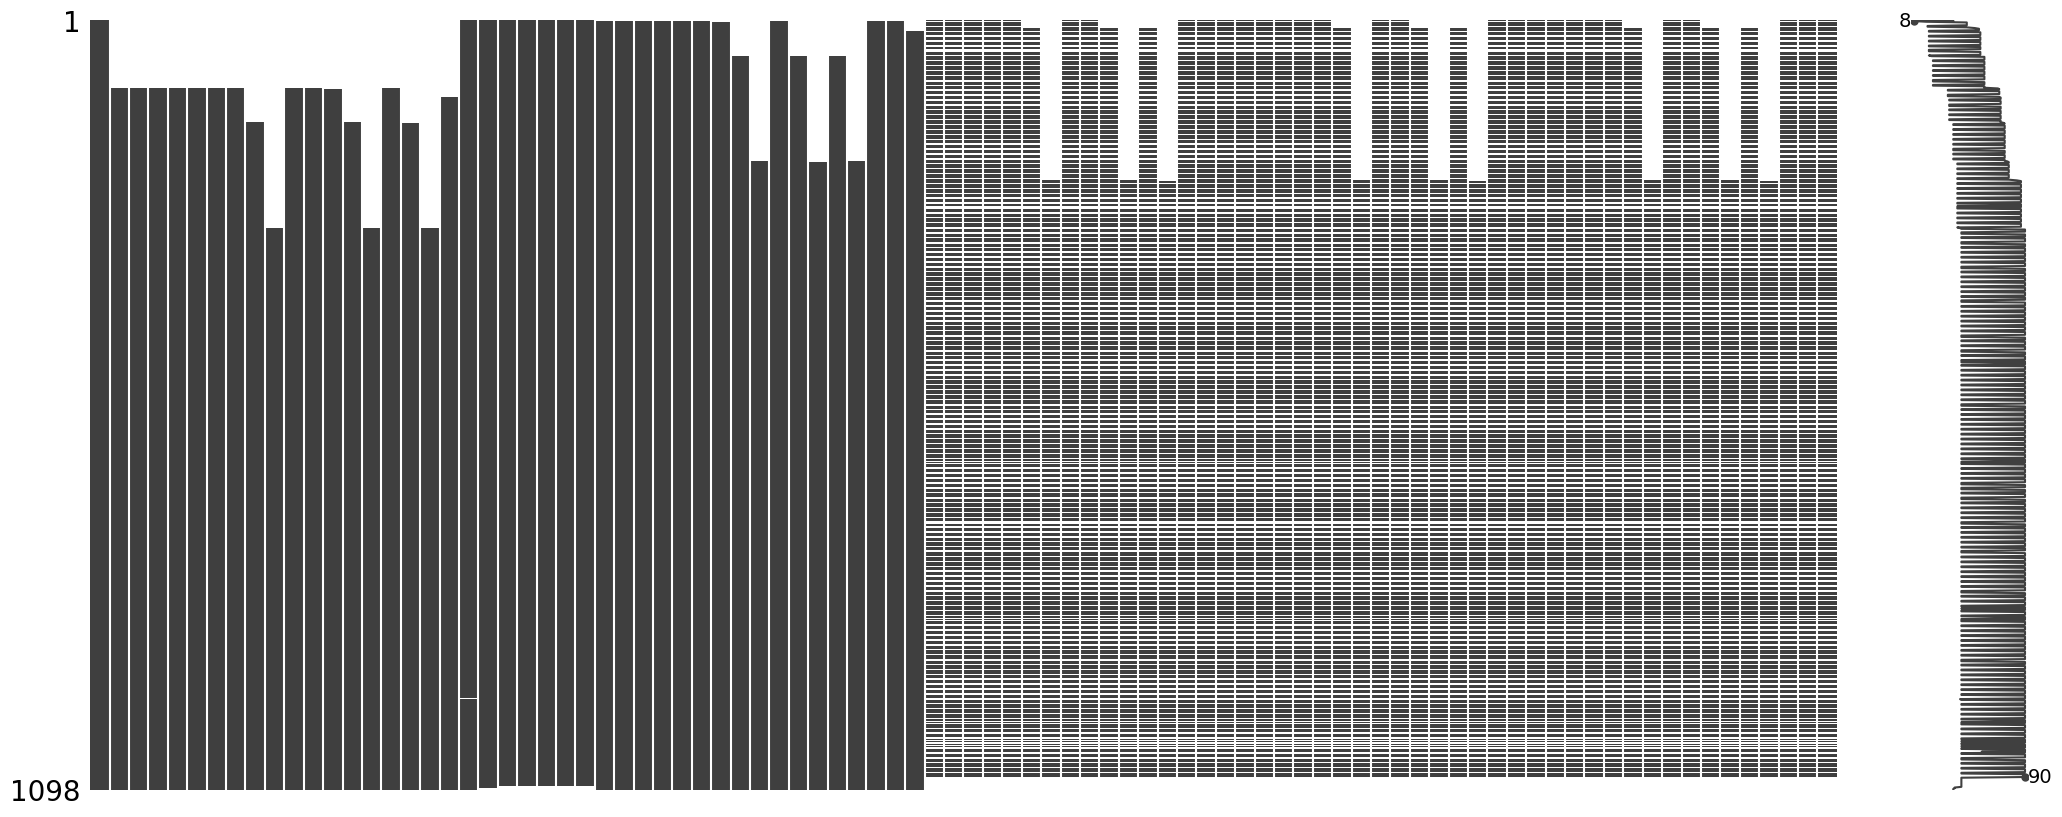

In [5]:
msno.matrix(df)

## 2. Correlaciones

### Relación precios de Bitcoin con otros activos (S&P 500, DXY, Nasdaq)

In [6]:
corr_matrix = df[['open_binance', 'high_binance', 'low_binance', 'close_binance', 'volume_binance', 'trades_binance',
                 'Close_sp500', 'High_sp500', 'Low_sp500', 'Open_sp500', 'Volume_sp500',
                 'Close_nasdaq', 'High_nasdaq', 'Low_nasdaq', 'Open_nasdaq', 'Volume_nasdaq',
                 'Close_dxy', 'High_dxy', 'Low_dxy', 'Open_dxy']].dropna().corr(method='pearson')

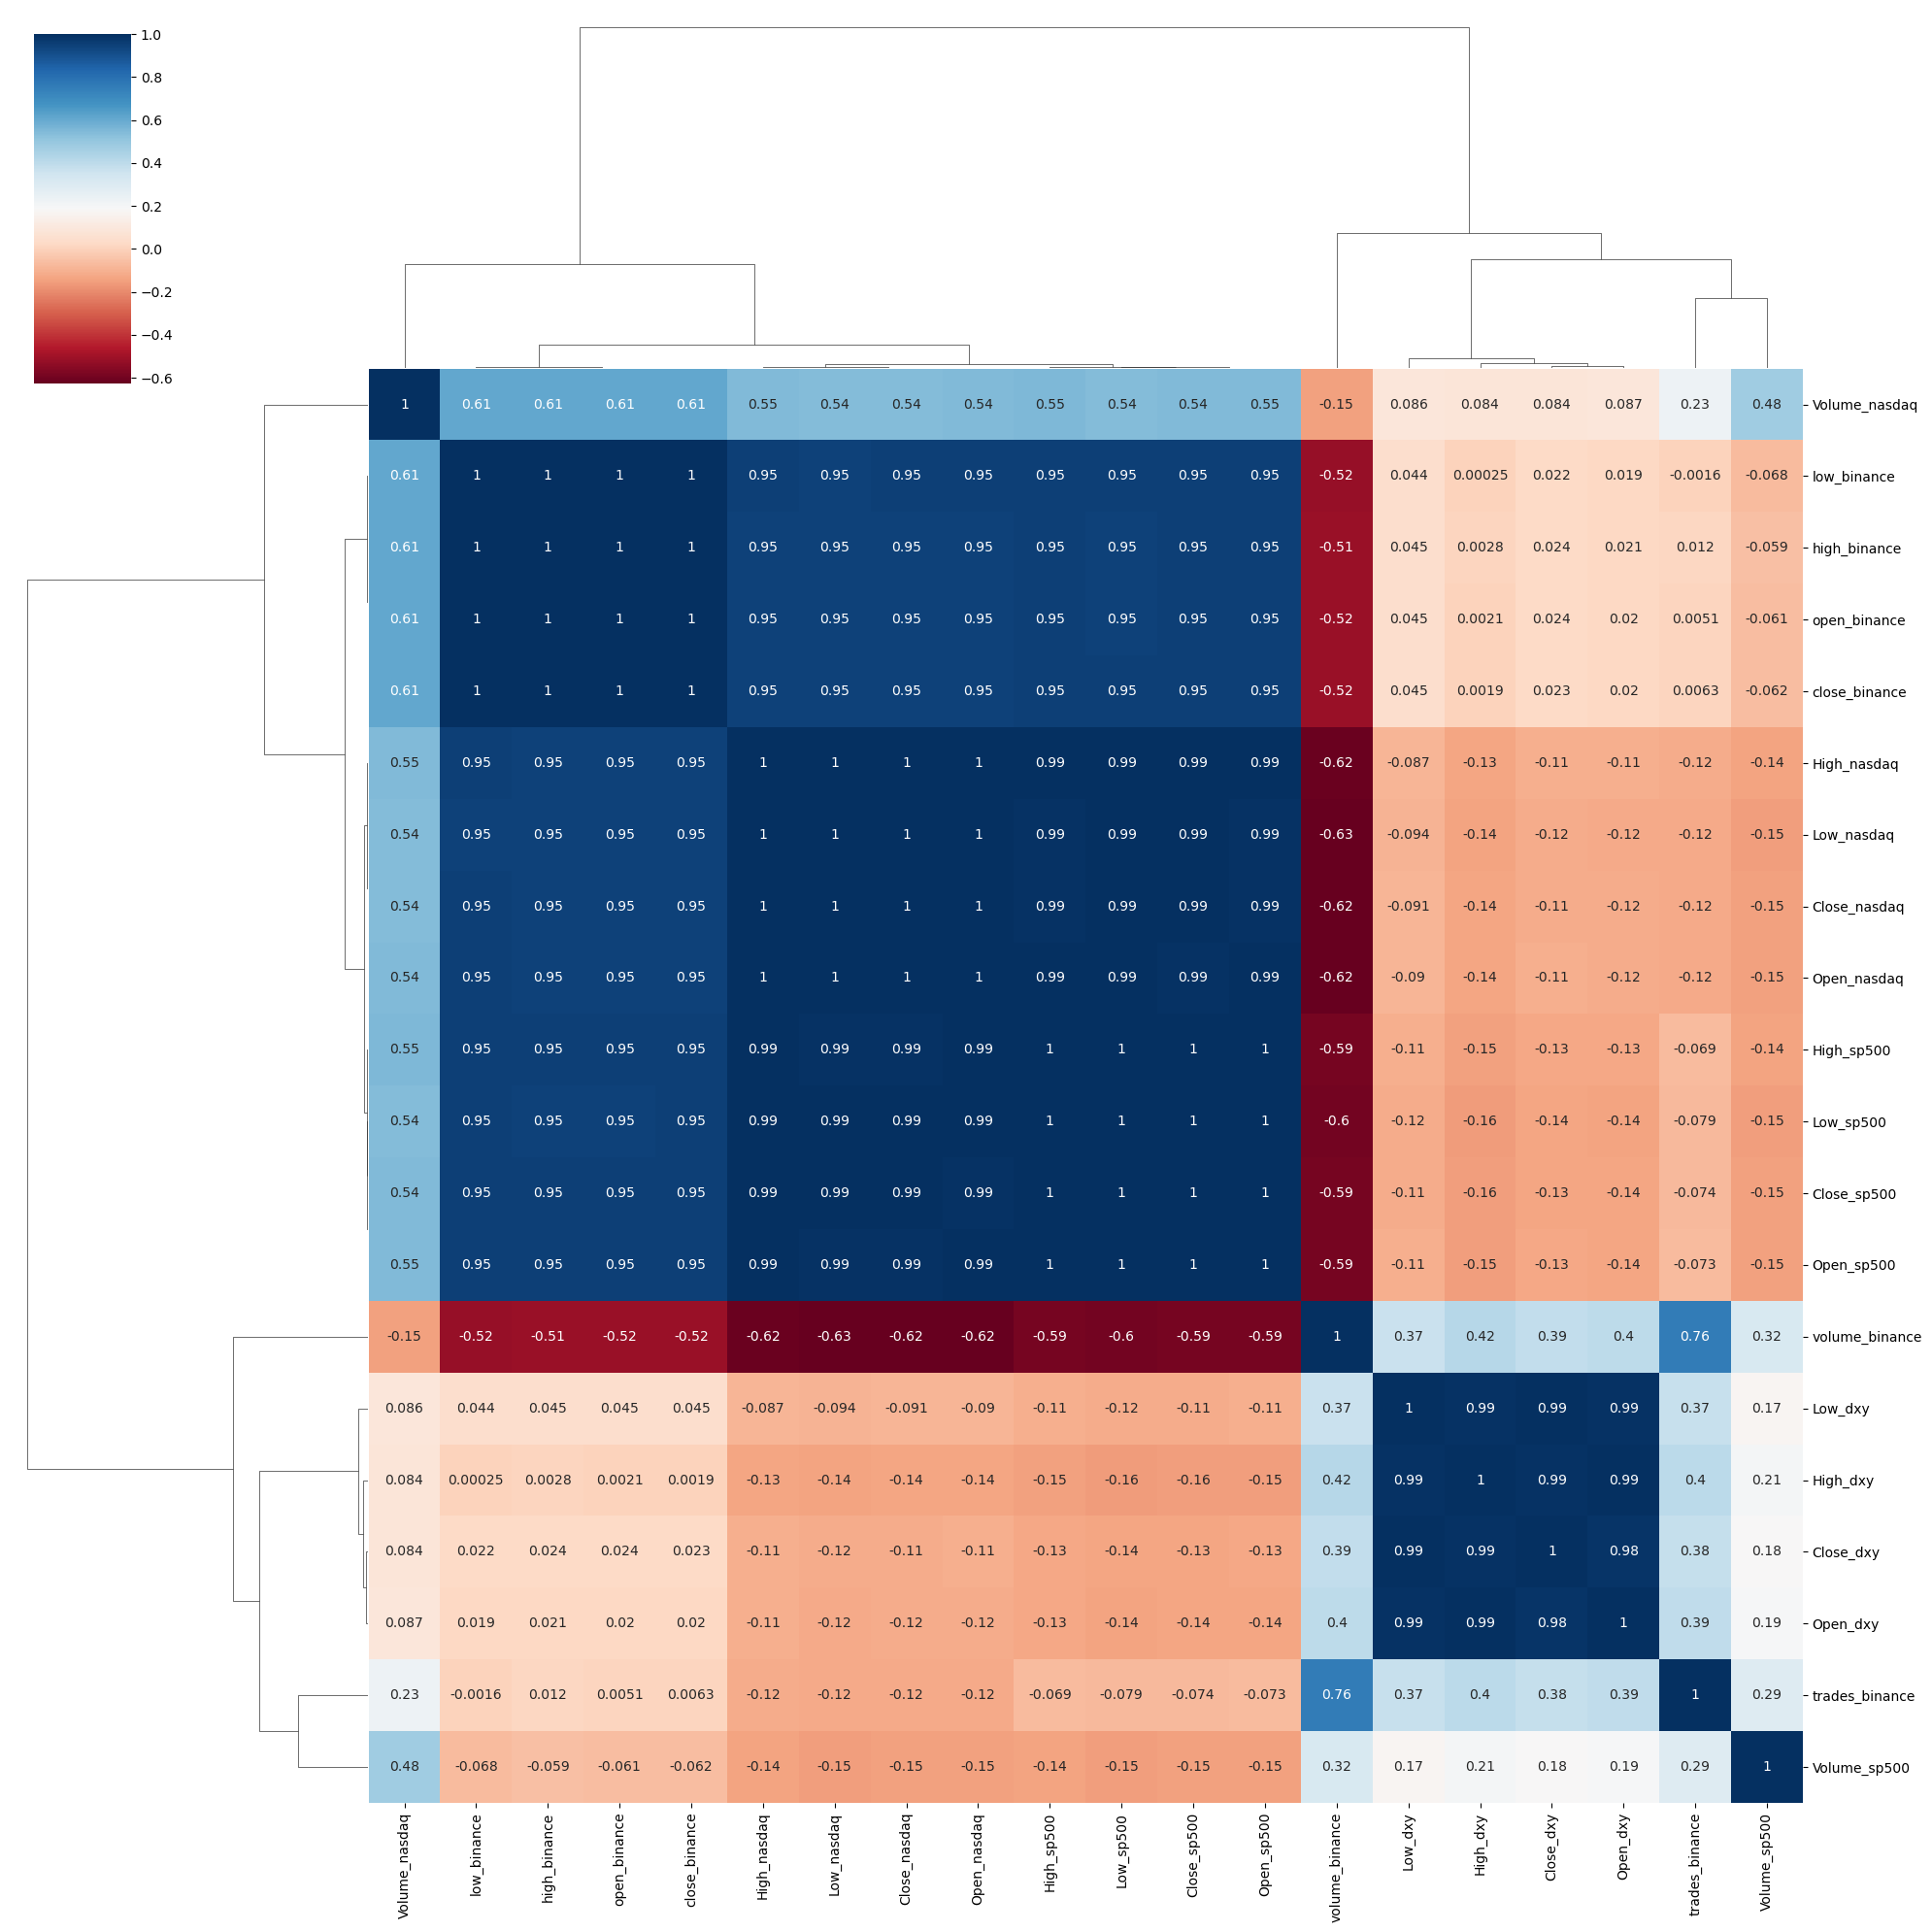

In [7]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 10}, # Tamaño de la fuente de las anotaciones
                   figsize=(20, 20))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()

### Tendencias en sentimientos del mercado (Fear & Greed Index, Google Trends)

In [8]:
filtro = df['bitcoin_gtrends'] == 0
df.loc[filtro, 'bitcoin_gtrends'] = None
df["bitcoin_gtrends"] = df["bitcoin_gtrends"].interpolate(method='linear')  # Interpolación lineal

In [15]:
corr_matrix = df[["close_binance", "volatilidad_50_binance", "volatilidad_200_binance", "var_diaria_binance",
                  "fear_greed_index_fg", "bitcoin_gtrends",
                  "Close_sp500", "Close_nasdaq", "Close_dxy"]].dropna().corr(method='spearman')

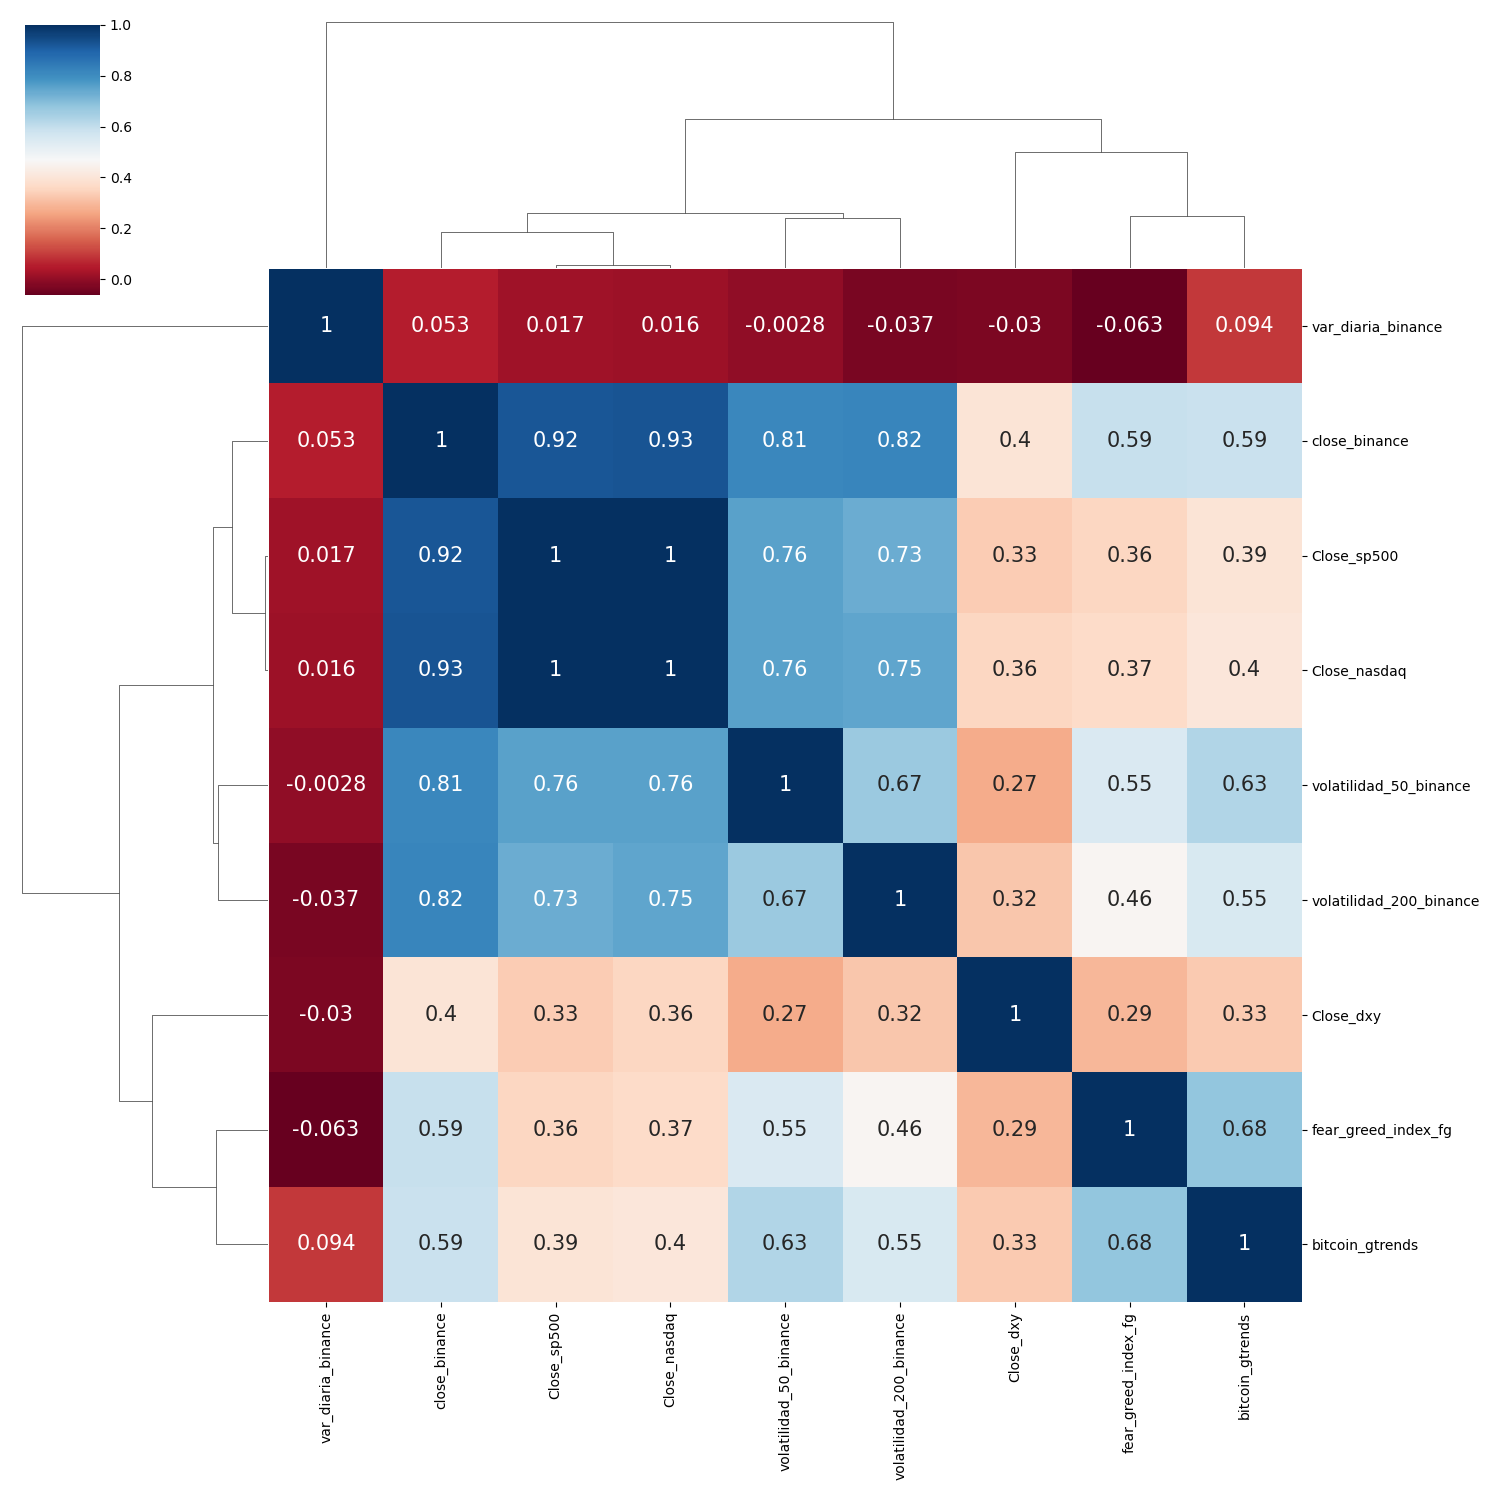

In [16]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 15}, # Tamaño de la fuente de las anotaciones
                   figsize=(15, 15))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()

### Relación entre volatilidad y precio

In [11]:
df_filtered = df[['close_binance', 'volatilidad_50_binance', 'volatilidad_200_binance', 'var_diaria_binance']].dropna()

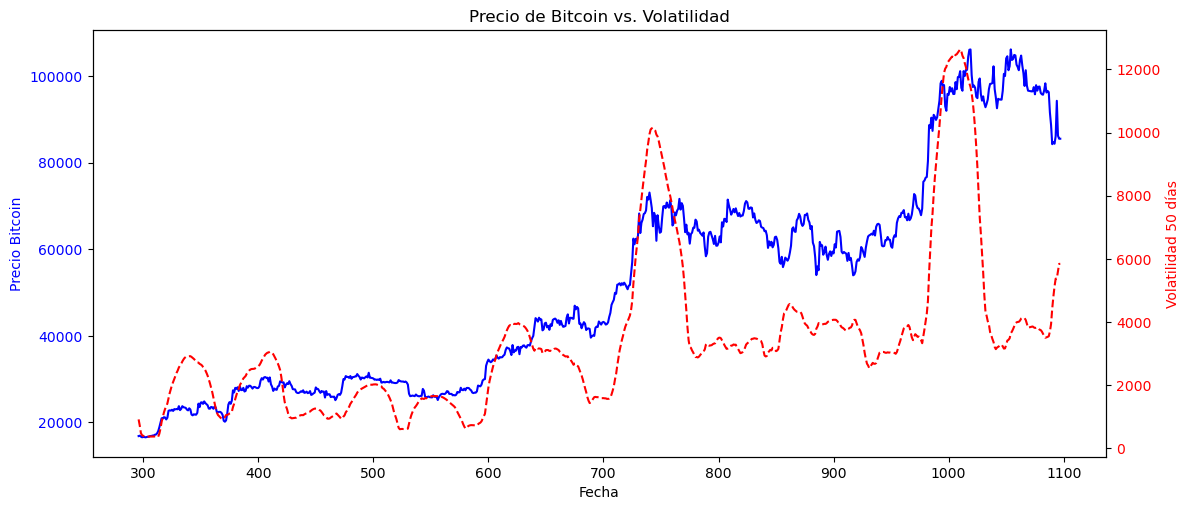

In [12]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Gráfica de precio (eje izquierdo)
ax1.set_xlabel('Fecha')
ax1.set_ylabel('Precio Bitcoin', color='blue')
ax1.plot(df_filtered.index, df_filtered['close_binance'], color='blue', label='Precio BTC')
ax1.tick_params(axis='y', labelcolor='blue')

# Agregar segundo eje Y para volatilidad
ax2 = ax1.twinx()
ax2.set_ylabel('Volatilidad 50 días', color='red')
ax2.plot(df_filtered.index, df_filtered['volatilidad_50_binance'], color='red', linestyle='dashed', label='Volatilidad 50 días')
ax2.tick_params(axis='y', labelcolor='red')

fig.tight_layout()
plt.title("Precio de Bitcoin vs. Volatilidad")
plt.show()

In [13]:
corr_matrix = df_filtered.corr(method='spearman')  # Spearman capta relaciones no lineales

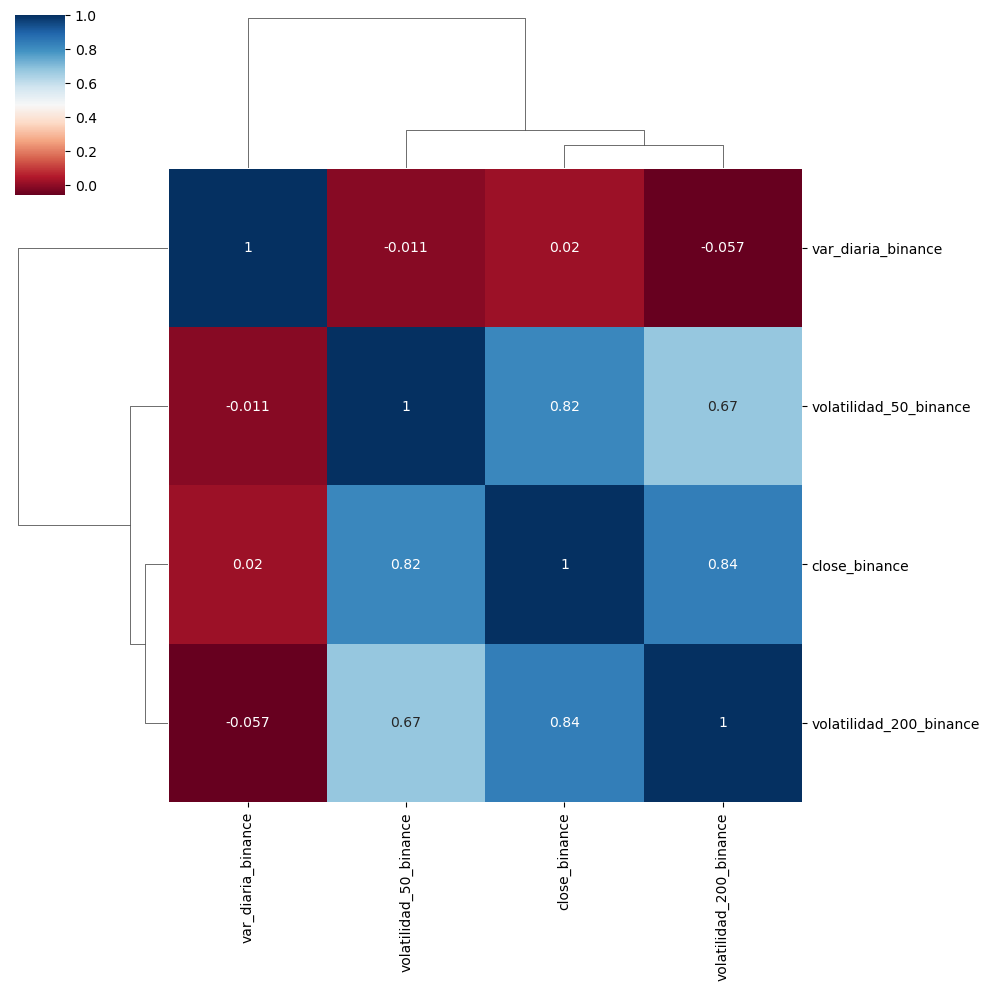

In [14]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 10}, # Tamaño de la fuente de las anotaciones
                   figsize=(10, 10))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()